# Лабораторная работа 2. Часть 2 — прикладной анализ интернет-магазина

**ФИО:** Мельников Артем Иванович  
**Группа:** ЕТ-216

Данные синтетические, не описывают реальную торговлю. Генератор построен самостоятельно: отдельные справочники клиентов и товаров обеспечивают согласованность повторных заказов. `cost` — себестоимость **всей позиции заказа**, поэтому формула `profit = revenue - cost` соответствует PDF. Каждый заказ содержит один вид товара в количестве `quantity`.

## 0. Создание 3000 заказов

Фиксированное зерно 2024 обеспечивает повторяемость. У одного клиента сохраняются город, возраст и VIP-статус; название товара связано с категорией. CSV сохраняет исходные пропуски.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
np.random.seed(2024)
cities = ['Москва','Санкт-Петербург','Казань','Екатеринбург','Челябинск']
categories = ['Электроника','Одежда','Дом','Красота','Спорт']
clients = pd.DataFrame({'customer_id': np.arange(1,701), 'city': np.random.choice(cities,700), 'age': np.random.randint(16,76,700), 'is_vip': np.random.choice([True,False],700,p=[0.23,0.77])})
products = pd.DataFrame({
 'product_name': ['Наушники','Клавиатура','Рубашка','Куртка','Лампа','Кресло','Крем','Парфюм','Коврик','Гантели'],
 'category': np.repeat(categories,2),
 'base_price': [6500,4200,2100,8500,3200,12000,1800,5600,2300,4800]
})
size = 3000
orders = pd.DataFrame({'order_id': np.arange(1,size+1), 'order_date': (pd.Timestamp('2023-01-01') + pd.to_timedelta(np.random.randint(0,731,size),unit='D')).strftime('%Y-%m-%d'), 'customer_id': np.random.randint(1,701,size), 'product_key': np.random.randint(0,len(products),size), 'quantity': np.random.randint(1,6,size)})
df = orders.merge(clients,on='customer_id',validate='many_to_one').merge(products,left_on='product_key',right_index=True,validate='many_to_one')
df['price'] = df.pop('base_price').astype(float)
df['discount'] = np.random.choice([0,0.05,0.1,0.15,0.25,0.35],size)
df['cost'] = (df['price'] * df['quantity'] * np.random.uniform(0.55,0.85,size)).round(2)
df['status'] = np.random.choice(['Доставлен','Отменён','Возврат'],size,p=[0.78,0.14,0.08])
df['payment'] = np.random.choice(['Карта','Онлайн','Наличные'],size)
df = df[['order_id','order_date','customer_id','city','age','is_vip','product_name','category','quantity','price','discount','cost','status','payment']].copy()
df['age'] = df['age'].astype(float)
df.loc[np.random.choice(df.index,30,replace=False),'age'] = np.nan
df.to_csv('orders_raw.csv',index=False)
df = pd.read_csv('orders_raw.csv')
display(df.head())

,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment
0,1,2023-12-12,437,Санкт-Петербург,60.0,False,Лампа,Дом,2,3200.0,0.35,4030.94,Возврат,Наличные
1,2,2024-10-15,437,Санкт-Петербург,60.0,False,Гантели,Спорт,5,4800.0,0.25,17813.57,Доставлен,Наличные
2,3,2023-03-17,668,Москва,72.0,False,Клавиатура,Электроника,4,4200.0,0.05,11513.15,Возврат,Карта
3,4,2023-02-10,507,Москва,72.0,False,Рубашка,Одежда,5,2100.0,0.00,8654.03,Доставлен,Наличные
4,5,2023-10-02,409,Москва,55.0,False,Парфюм,Красота,2,5600.0,0.10,6797.91,Отменён,Наличные


## 1. Первичный анализ

Проверяем структуру до обработки пропусков. Частоты и списки ниже описывают именно заказы, а не отдельную выборку людей.

In [2]:
print('Размер:',df.shape)
df.info()
display(df.head(),df.tail(),df.describe(),df.isna().sum().rename('Пропуски'))
print('Клиентов:',df['customer_id'].nunique(),'Товаров:',df['product_name'].nunique())
for column in ['city','category','payment']:
 print(column, sorted(df[column].unique()))
assert df.shape == (3000,14)
assert df['order_id'].is_unique and df['age'].isna().sum() == 30

Размер: (3000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   order_id      3000 non-null   int64  
 1   order_date    3000 non-null   object 
 2   customer_id   3000 non-null   int64  
 3   city          3000 non-null   object 
 4   age           2970 non-null   float64
 5   is_vip        3000 non-null   bool   
 6   product_name  3000 non-null   object 
 7   category      3000 non-null   object 
 8   quantity      3000 non-null   int64  
 9   price         3000 non-null   float64
 10  discount      3000 non-null   float64
 11  cost          3000 non-null   float64
 12  status        3000 non-null   object 
 13  payment       3000 non-null   object 
dtypes: bool(1), float64(4), int64(3), object(6)
memory usage: 307.7+ KB


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment
0,1,2023-12-12,437,Санкт-Петербург,60.0,False,Лампа,Дом,2,3200.0,0.35,4030.94,Возврат,Наличные
1,2,2024-10-15,437,Санкт-Петербург,60.0,False,Гантели,Спорт,5,4800.0,0.25,17813.57,Доставлен,Наличные
2,3,2023-03-17,668,Москва,72.0,False,Клавиатура,Электроника,4,4200.0,0.05,11513.15,Возврат,Карта
3,4,2023-02-10,507,Москва,72.0,False,Рубашка,Одежда,5,2100.0,0.00,8654.03,Доставлен,Наличные
4,5,2023-10-02,409,Москва,55.0,False,Парфюм,Красота,2,5600.0,0.10,6797.91,Отменён,Наличные


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment
2995,2996,2024-10-19,653,Казань,36.0,True,Куртка,Одежда,4,8500.0,0.05,26948.27,Доставлен,Онлайн
2996,2997,2023-01-24,108,Екатеринбург,56.0,False,Куртка,Одежда,1,8500.0,0.15,6268.87,Доставлен,Карта
2997,2998,2024-11-16,441,Москва,22.0,False,Парфюм,Красота,2,5600.0,0.05,9255.96,Доставлен,Онлайн
2998,2999,2023-04-18,360,Санкт-Петербург,38.0,False,Наушники,Электроника,5,6500.0,0.05,18021.08,Доставлен,Онлайн
2999,3000,2023-05-28,146,Екатеринбург,59.0,False,Крем,Красота,3,1800.0,0.25,3614.75,Доставлен,Онлайн


,order_id,customer_id,age,quantity,price,discount,cost
count,3000.000000,3000.000000,2970.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,1500.500000,351.798333,45.997980,3.003667,4994.833333,0.150283,10568.144853
std,866.169729,200.216759,17.126282,1.409367,3021.064754,0.119264,8793.927198
min,1.000000,1.000000,16.000000,1.000000,1800.000000,0.000000,995.850000
25%,750.750000,179.750000,31.000000,2.000000,2300.000000,0.050000,4204.537500
50%,1500.500000,355.000000,46.000000,3.000000,4200.000000,0.150000,7521.130000
75%,2250.250000,523.000000,60.000000,4.000000,6500.000000,0.250000,14385.295000
max,3000.000000,700.000000,75.000000,5.000000,12000.000000,0.350000,50080.980000


,Пропуски
order_id,0
order_date,0
customer_id,0
city,0
age,30
is_vip,0
product_name,0
category,0
quantity,0
price,0


Клиентов: 694 Товаров: 10
city ['Екатеринбург', 'Казань', 'Москва', 'Санкт-Петербург', 'Челябинск']
category ['Дом', 'Красота', 'Одежда', 'Спорт', 'Электроника']
payment ['Карта', 'Наличные', 'Онлайн']


## 2. Подготовка данных

Считаем показатели для всех заказов по формулам задания. Для фактических продаж создаём отдельную таблицу delivered. Интервалы возраста оставлены как в PDF: при правой включённой границе 18 попадает в первую группу, 60 — в четвёртую; точные границы показаны в результатах.

In [3]:
df['order_date'] = pd.to_datetime(df['order_date'])
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month
df['revenue'] = df['price'] * df['quantity'] * (1-df['discount'])
df['profit'] = df['revenue'] - df['cost']
df['is_real_sale'] = df['status'].eq('Доставлен')
median_age = df['age'].median()
df['age'] = df['age'].fillna(median_age)
labels = ['до 18','18–30','31–45','46–60','60+']
df['age_group'] = pd.cut(df['age'],bins=[0,18,30,45,60,100],labels=labels)
print('Медиана для заполнения:',median_age,'; осталось пропусков:',df['age'].isna().sum())
print('Интервалы: (0,18], (18,30], (30,45], (45,60], (60,100]')
display(df['age_group'].value_counts(sort=False))
print('Заказов с отрицательной расчётной прибылью:',df['profit'].lt(0).sum())
delivered = df.loc[df['is_real_sale']].copy()
df.to_csv('orders_prepared.csv',index=False)

Медиана для заполнения: 46.0 ; осталось пропусков: 0
Интервалы: (0,18], (18,30], (30,45], (45,60], (60,100]


,count
age_group,
до 18,146
18–30,543
31–45,719
46–60,883
60+,709


Заказов с отрицательной расчётной прибылью: 502


При большой скидке выручка может оказаться ниже полной себестоимости позиции, давая отрицательную прибыль. Суммы revenue для отмен и возвратов — расчётная стоимость, а не полученные деньги; фактическая выручка далее отдельно считается по доставленным заказам. Заполнение медианой не восстанавливает настоящий возраст и немного меняет распределение.

## 3. Фильтрация

Каждый результат хранится полностью в словаре selections; для компактного просмотра выводим число совпадений и первые пять строк.

In [4]:
selections = {}
selections['1. Количество больше 3'] = df.loc[df['quantity'] > 3].copy()
selections['2. Москва'] = df.loc[df['city'].eq('Москва')].copy()
selections['3. VIP'] = df.loc[df['is_vip']].copy()
selections['4. Цена выше 5000'] = df.loc[df['price'] > 5000].copy()
selections['5. Скидка выше 20%'] = df.loc[df['discount'] > 0.20].copy()
selections['7. Москва и выручка выше 5000'] = df.loc[df['city'].eq('Москва') & df['revenue'].gt(5000)].copy()
selections['8. VIP и электроника'] = df.loc[df['is_vip'] & df['category'].eq('Электроника')].copy()
selections['9. Доставка и онлайн-оплата'] = df.loc[df['is_real_sale'] & df['payment'].eq('Онлайн')].copy()
selections['10. Заказы 2024 года'] = df.loc[df['year'].eq(2024)].copy()
selections['11. Январь 2024'] = df.loc[df['year'].eq(2024) & df['month'].eq(1)].copy()
for title, subset in selections.items():
 print(title, '— найдено:', len(subset))
 display(subset.head())
print('6. Статусы:')
display(df['status'].value_counts())

1. Количество больше 3 — найдено: 1215


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
1,2,2024-10-15,437,Санкт-Петербург,60.0,False,Гантели,Спорт,5,4800.0,0.25,17813.57,Доставлен,Наличные,2024,10,18000.0,186.43,True,46–60
2,3,2023-03-17,668,Москва,72.0,False,Клавиатура,Электроника,4,4200.0,0.05,11513.15,Возврат,Карта,2023,3,15960.0,4446.85,False,60+
3,4,2023-02-10,507,Москва,72.0,False,Рубашка,Одежда,5,2100.0,0.00,8654.03,Доставлен,Наличные,2023,2,10500.0,1845.97,True,60+
5,6,2024-04-06,95,Москва,33.0,False,Рубашка,Одежда,4,2100.0,0.05,6455.45,Доставлен,Карта,2024,4,7980.0,1524.55,True,31–45
6,7,2024-02-28,691,Челябинск,74.0,False,Куртка,Одежда,4,8500.0,0.25,19433.28,Возврат,Онлайн,2024,2,25500.0,6066.72,False,60+


2. Москва — найдено: 567


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
2,3,2023-03-17,668,Москва,72.0,False,Клавиатура,Электроника,4,4200.0,0.05,11513.15,Возврат,Карта,2023,3,15960.0,4446.85,False,60+
3,4,2023-02-10,507,Москва,72.0,False,Рубашка,Одежда,5,2100.0,0.00,8654.03,Доставлен,Наличные,2023,2,10500.0,1845.97,True,60+
4,5,2023-10-02,409,Москва,55.0,False,Парфюм,Красота,2,5600.0,0.10,6797.91,Отменён,Наличные,2023,10,10080.0,3282.09,False,46–60
5,6,2024-04-06,95,Москва,33.0,False,Рубашка,Одежда,4,2100.0,0.05,6455.45,Доставлен,Карта,2024,4,7980.0,1524.55,True,31–45
8,9,2023-07-27,204,Москва,18.0,True,Лампа,Дом,4,3200.0,0.25,8636.22,Возврат,Карта,2023,7,9600.0,963.78,False,до 18


3. VIP — найдено: 681


...

,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
1,2,2024-10-15,437,Санкт-Петербург,60.0,False,Гантели,Спорт,5,4800.0,0.25,17813.57,Доставлен,Наличные,2024,10,18000.0,186.43,True,46–60
5,6,2024-04-06,95,Москва,33.0,False,Рубашка,Одежда,4,2100.0,0.05,6455.45,Доставлен,Карта,2024,4,7980.0,1524.55,True,31–45
6,7,2024-02-28,691,Челябинск,74.0,False,Куртка,Одежда,4,8500.0,0.25,19433.28,Возврат,Онлайн,2024,2,25500.0,6066.72,False,60+
10,11,2024-11-06,72,Москва,49.0,False,Куртка,Одежда,2,8500.0,0.10,13771.18,Доставлен,Наличные,2024,11,15300.0,1528.82,True,46–60
12,13,2024-05-14,132,Казань,57.0,False,Коврик,Спорт,4,2300.0,0.00,5195.48,Доставлен,Карта,2024,5,9200.0,4004.52,True,46–60


11. Январь 2024 — найдено: 131


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
39,40,2024-01-12,506,Москва,45.0,True,Кресло,Дом,3,12000.0,0.05,25494.57,Доставлен,Онлайн,2024,1,34200.0,8705.43,True,31–45
64,65,2024-01-09,497,Казань,26.0,True,Гантели,Спорт,4,4800.0,0.00,14175.61,Доставлен,Онлайн,2024,1,19200.0,5024.39,True,18–30
67,68,2024-01-17,490,Екатеринбург,66.0,True,Наушники,Электроника,4,6500.0,0.25,14457.74,Отменён,Онлайн,2024,1,19500.0,5042.26,False,60+
101,102,2024-01-29,335,Москва,42.0,False,Куртка,Одежда,4,8500.0,0.15,27345.46,Доставлен,Карта,2024,1,28900.0,1554.54,True,31–45
106,107,2024-01-07,486,Москва,60.0,True,Рубашка,Одежда,4,2100.0,0.15,6859.77,Доставлен,Наличные,2024,1,7140.0,280.23,True,46–60


6. Статусы:


,count
status,
Доставлен,2359
Отменён,403
Возврат,238


## 3. Поиск экстремумов

idxmax и idxmin возвращают индекс первой строки с экстремальным значением. При одинаковых значениях показываем первый из подходящих заказов.

In [5]:
for title,column,method in [('Максимальная выручка','revenue','idxmax'),('Максимальная скидка','discount','idxmax'),('Максимальная прибыль','profit','idxmax'),('Минимальный возраст','age','idxmin'),('Максимальный возраст','age','idxmax')]:
 index = getattr(df[column],method)()
 print(title)
 display(df.loc[[index]])

Максимальная выручка


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
131,132,2024-01-15,454,Санкт-Петербург,66.0,False,Кресло,Дом,5,12000.0,0.0,47144.04,Доставлен,Онлайн,2024,1,60000.0,12855.96,True,60+


Максимальная скидка


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
0,1,2023-12-12,437,Санкт-Петербург,60.0,False,Лампа,Дом,2,3200.0,0.35,4030.94,Возврат,Наличные,2023,12,4160.0,129.06,False,46–60


Максимальная прибыль


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
2814,2815,2024-04-01,162,Челябинск,21.0,False,Кресло,Дом,5,12000.0,0.0,36344.11,Отменён,Наличные,2024,4,60000.0,23655.89,False,18–30


Минимальный возраст


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
57,58,2024-04-20,401,Москва,16.0,False,Парфюм,Красота,5,5600.0,0.15,21279.04,Доставлен,Карта,2024,4,23800.0,2520.96,True,до 18


Максимальный возраст


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment,year,month,revenue,profit,is_real_sale,age_group
18,19,2024-04-03,336,Москва,75.0,False,Парфюм,Красота,4,5600.0,0.05,12665.13,Доставлен,Карта,2024,4,21280.0,8614.87,True,60+


## 4. Группировка: задания 1–8

Основные таблицы используют все статусы, как в примерах PDF. Итоговая сводка объединяет показатели по категориям; дополнительно сравниваем доставленные заказы.

In [6]:
category_stats = df.groupby('category').agg(orders=('order_id','count'),revenue=('revenue','sum'),avg_revenue=('revenue','mean'),avg_discount=('discount','mean'),profit=('profit','sum'))
display(category_stats.sort_values('revenue',ascending=False))
print('5. Выручка по категории и городу')
display(df.groupby(['category','city'])['revenue'].sum())
print('6. Средняя выручка VIP-заказа по городам')
display(df.loc[df['is_vip']].groupby('city')['revenue'].mean())
print('7. Количество по городу и оплате')
display(df.groupby(['city','payment']).size().unstack(fill_value=0))
real_category = delivered.groupby('category')['revenue'].sum()
display(real_category.rename('Выручка доставленных заказов'))

,orders,revenue,avg_revenue,avg_discount,profit
category,,,,,
Дом,589,11158720.0,18945.195246,0.152632,2063281.71
Одежда,629,8156885.0,12968.020668,0.153021,1404382.34
Электроника,579,8107070.0,14001.848014,0.151727,1398135.64
Красота,608,5721640.0,9410.592105,0.142599,1077070.37
Спорт,595,5502935.0,9248.630252,0.151513,999945.38


5. Выручка по категории и городу


category     city           
Дом          Екатеринбург       2317480.0
             Казань             2377360.0
             Москва             1920440.0
             Санкт-Петербург    2245480.0
             Челябинск          2297960.0
Красота      Екатеринбург       1246080.0
             Казань             1368980.0
             Москва             1105460.0
             Санкт-Петербург    1045310.0
             Челябинск           955810.0
Одежда       Екатеринбург       1536835.0
             Казань             1543275.0
             Москва             1567510.0
             Санкт-Петербург    1799780.0
             Челябинск          1709485.0
Спорт        Екатеринбург        979665.0
             Казань             1149890.0
             Москва             1077170.0
             Санкт-Петербург    1107805.0
             Челябинск          1188405.0
Электроника  Екатеринбург       1508340.0
             Казань             1716095.0
             Москва             1512605.0
             Санкт-Петербург    1723780.0
             Челябинск          1646250.0
Name: revenue, dtype: float64

6. Средняя выручка VIP-заказа по городам


,revenue
city,
Екатеринбург,13768.760684
Казань,12386.952663
Москва,13493.101852
Санкт-Петербург,11988.740741
Челябинск,13584.967105


7. Количество по городу и оплате


payment,Карта,Наличные,Онлайн
city,,,
Екатеринбург,185,184,188
Казань,222,211,223
Москва,192,180,195
Санкт-Петербург,207,222,189
Челябинск,192,219,191


,Выручка доставленных заказов
category,
Дом,8949880.0
Красота,4487720.0
Одежда,6384725.0
Спорт,4142450.0
Электроника,6564540.0


## 5.1. Распределение возраста

График построен по заказам; повторные клиенты учитываются повторно.

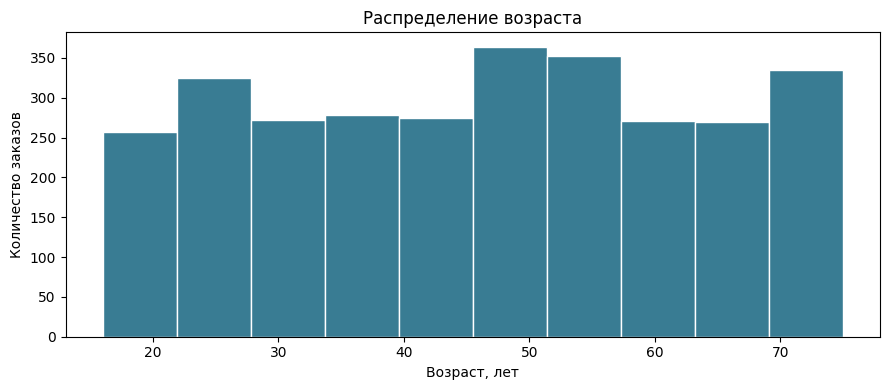

In [7]:
fig, ax = plt.subplots(figsize=(9,4))
ax.hist(df['age'],bins=10,color='#397c93',edgecolor='white')
ax.set(title='Распределение возраста',xlabel='Возраст, лет',ylabel='Количество заказов')
fig.tight_layout()
plt.show()

## 5.2. Распределение расчётной выручки

График построен по заказам; повторные клиенты учитываются повторно.

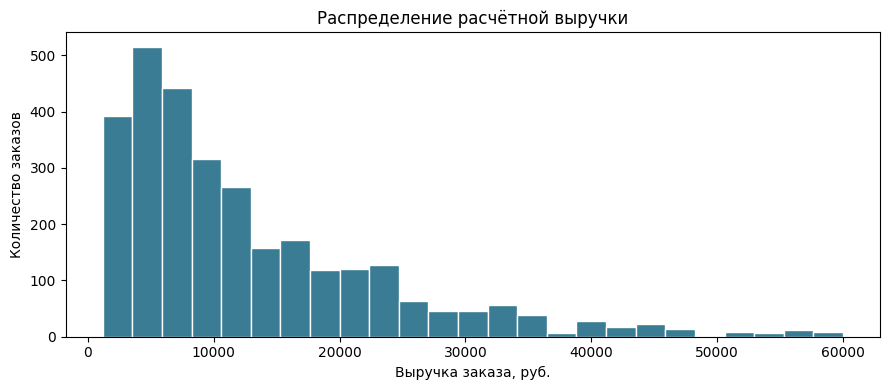

In [8]:
fig, ax = plt.subplots(figsize=(9,4))
ax.hist(df['revenue'],bins=25,color='#397c93',edgecolor='white')
ax.set(title='Распределение расчётной выручки',xlabel='Выручка заказа, руб.',ylabel='Количество заказов')
fig.tight_layout()
plt.show()

## 5.3. Распределение скидки

График построен по заказам; повторные клиенты учитываются повторно.

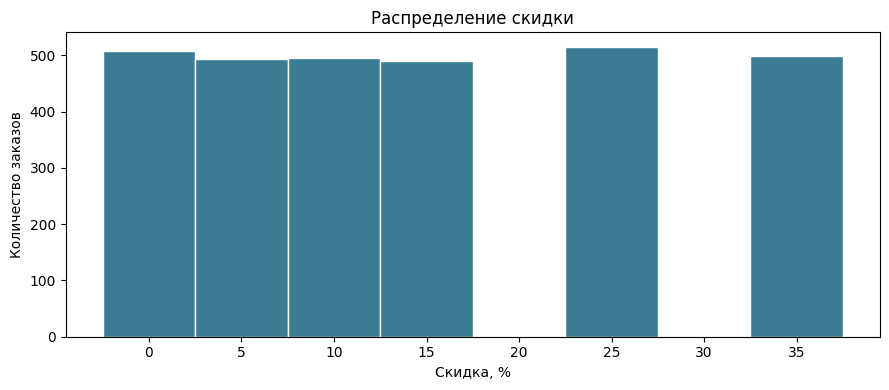

In [9]:
fig, ax = plt.subplots(figsize=(9,4))
ax.hist(df['discount']*100,bins=[-2.5,2.5,7.5,12.5,17.5,22.5,27.5,32.5,37.5],color='#397c93',edgecolor='white')
ax.set(title='Распределение скидки',xlabel='Скидка, %',ylabel='Количество заказов')
fig.tight_layout()
plt.show()

## 5.4. Возраст в VIP и обычных заказах

График построен по заказам; повторные клиенты учитываются повторно.

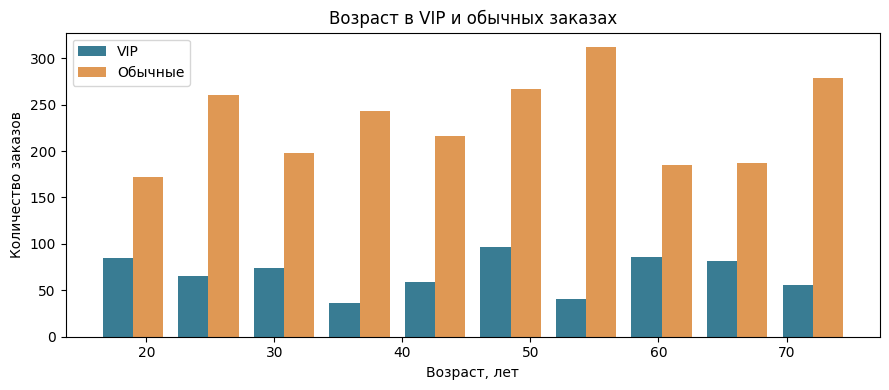

In [10]:
fig, ax = plt.subplots(figsize=(9,4))
ax.hist([df.loc[df['is_vip'],'age'],df.loc[~df['is_vip'],'age']],bins=10,label=['VIP','Обычные'],color=['#397c93','#df9854'])
ax.legend()
ax.set(title='Возраст в VIP и обычных заказах',xlabel='Возраст, лет',ylabel='Количество заказов')
fig.tight_layout()
plt.show()

## 5.5. Расчётная выручка по категориям

График построен по заказам; повторные клиенты учитываются повторно.

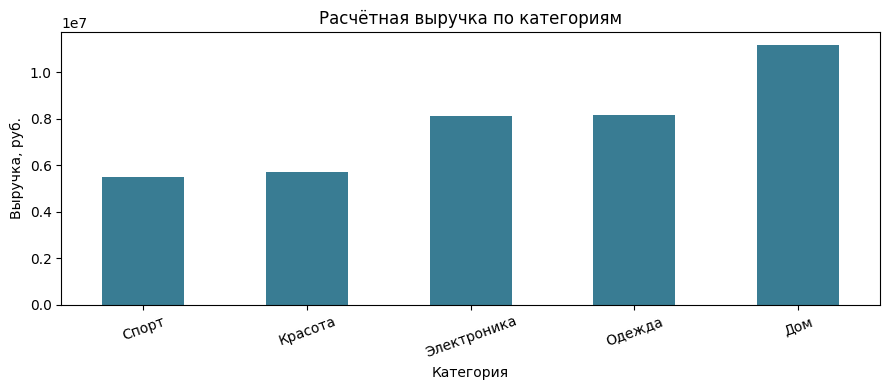

In [11]:
fig, ax = plt.subplots(figsize=(9,4))
category_stats['revenue'].sort_values().plot.bar(ax=ax,color='#397c93',rot=20)
ax.set(title='Расчётная выручка по категориям',xlabel='Категория',ylabel='Выручка, руб.')
fig.tight_layout()
plt.show()

## 5.6. Заказы по городам

График построен по заказам; повторные клиенты учитываются повторно.

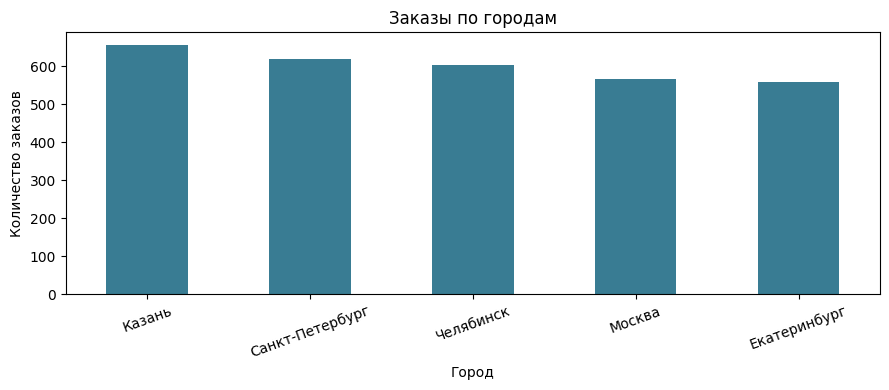

In [12]:
fig, ax = plt.subplots(figsize=(9,4))
df['city'].value_counts().plot.bar(ax=ax,color='#397c93',rot=20)
ax.set(title='Заказы по городам',xlabel='Город',ylabel='Количество заказов')
fig.tight_layout()
plt.show()

## 5.7. Заказы по возрастным группам

График построен по заказам; повторные клиенты учитываются повторно.

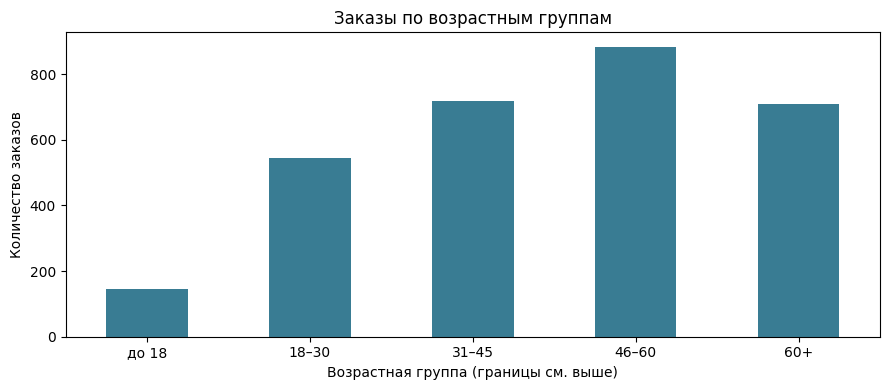

In [13]:
fig, ax = plt.subplots(figsize=(9,4))
df['age_group'].value_counts(sort=False).plot.bar(ax=ax,color='#397c93',rot=0)
ax.set(title='Заказы по возрастным группам',xlabel='Возрастная группа (границы см. выше)',ylabel='Количество заказов')
fig.tight_layout()
plt.show()

## 5.8. Статусы заказов

График построен по заказам; повторные клиенты учитываются повторно.

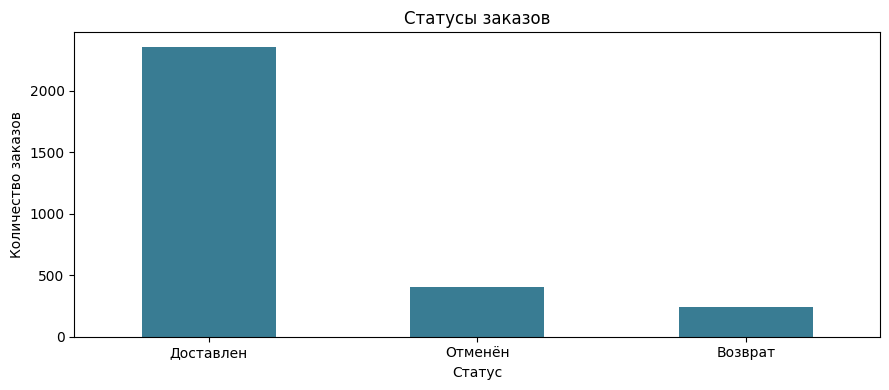

In [14]:
fig, ax = plt.subplots(figsize=(9,4))
df['status'].value_counts().plot.bar(ax=ax,color='#397c93',rot=0)
ax.set(title='Статусы заказов',xlabel='Статус',ylabel='Количество заказов')
fig.tight_layout()
plt.show()

## 5.9. Выручка по месяцам

График построен по заказам; повторные клиенты учитываются повторно.

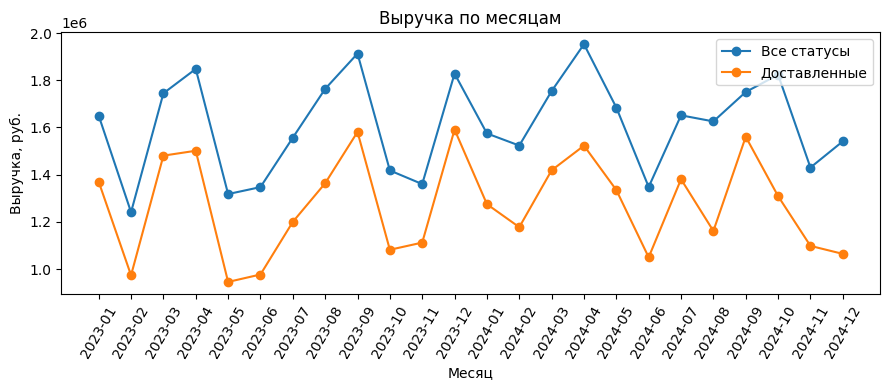

In [15]:
fig, ax = plt.subplots(figsize=(9,4))
monthly = df.groupby(['year','month'])['revenue'].sum()
real_monthly = delivered.groupby(['year','month'])['revenue'].sum().reindex(monthly.index,fill_value=0)
x = np.arange(len(monthly))
ax.plot(x,monthly.to_numpy(),label='Все статусы',marker='o')
ax.plot(x,real_monthly.to_numpy(),label='Доставленные',marker='o')
ax.set_xticks(x,[f'{y}-{m:02d}' for y,m in monthly.index],rotation=60)
ax.legend()
ax.set(title='Выручка по месяцам',xlabel='Месяц',ylabel='Выручка, руб.')
fig.tight_layout()
plt.show()

## 5.9. Вывод по динамике

Сравниваем месяцы по фактически доставленным заказам.

In [16]:
peak = real_monthly.idxmax()
low = real_monthly.idxmin()
display(Markdown(f'Максимум выручки доставленных заказов приходится на {peak[0]}-{peak[1]:02d}, минимум — на {low[0]}-{low[1]:02d}. Колебания в этих синтетических данных сами по себе не доказывают сезонность.'))

Максимум выручки доставленных заказов приходится на 2023-12, минимум — на 2023-05. Колебания в этих синтетических данных сами по себе не доказывают сезонность.

## 6.1. Общая статистика

Разделяем расчётную стоимость всех заказов и выручку доставленных.

In [17]:
total = df['revenue'].sum()
real_total = delivered['revenue'].sum()
display(Markdown(f"Всего {len(df)} заказов; их расчётная выручка {total:,.2f} руб., средняя {df['revenue'].mean():,.2f} руб. Доставлено {len(delivered)} заказов с выручкой {real_total:,.2f} руб.; именно эту сумму принимаем за фактическую выручку в рамках модели."))

Всего 3000 заказов; их расчётная выручка 38,647,250.00 руб., средняя 12,882.42 руб. Доставлено 2359 заказов с выручкой 30,529,315.00 руб.; именно эту сумму принимаем за фактическую выручку в рамках модели.

## 6.2. Категории

Показываем лидера и минимальную категорию для обеих баз расчёта.

In [18]:
display(category_stats['revenue'].sort_values(ascending=False))
display(Markdown(f"По всем статусам лидирует «{category_stats['revenue'].idxmax()}», минимум у «{category_stats['revenue'].idxmin()}». Среди доставленных заказов лидер — «{real_category.idxmax()}», минимум — «{real_category.idxmin()}»; это сравнение сумм, а не рентабельности."))

,revenue
category,
Дом,11158720.0
Одежда,8156885.0
Электроника,8107070.0
Красота,5721640.0
Спорт,5502935.0


По всем статусам лидирует «Дом», минимум у «Спорт». Среди доставленных заказов лидер — «Дом», минимум — «Спорт»; это сравнение сумм, а не рентабельности.

## 6.3. Вклад VIP

Доля считается в денежной выручке, а не в числе заказов.

In [19]:
vip_share = df.loc[df['is_vip'],'revenue'].sum()/total
real_vip_share = delivered.loc[delivered['is_vip'],'revenue'].sum()/real_total
display(Markdown(f'VIP-заказы дают {vip_share:.2%} расчётной выручки всех статусов и {real_vip_share:.2%} выручки доставленных заказов. Эти доли описывают вклад сегмента, но не объясняют причины его покупательского поведения.'))

VIP-заказы дают 22.89% расчётной выручки всех статусов и 22.19% выручки доставленных заказов. Эти доли описывают вклад сегмента, но не объясняют причины его покупательского поведения.

## 6.4. Скидки

Группируем скидки, включая нулевые; сравнение наблюдательное.

In [20]:
df['discount_group'] = pd.cut(df['discount'],bins=[-0.001,0,0.1,0.2,1],labels=['Без скидки','До 10%','Свыше 10% до 20%','Свыше 20%'])
discount_stats = df.groupby('discount_group',observed=False).agg(orders=('order_id','size'),avg_revenue=('revenue','mean'))
display(discount_stats)
display(Markdown(f"Самая высокая средняя расчётная выручка в группе «{discount_stats['avg_revenue'].idxmax()}». Различия зависят также от цены и количества: по этой таблице нельзя утверждать, что скидка вызвала рост или снижение продаж."))

,orders,avg_revenue
discount_group,,
Без скидки,507,15275.147929
До 10%,990,14273.005051
Свыше 10% до 20%,490,13099.887755
Свыше 20%,1013,10220.661402


Самая высокая средняя расчётная выручка в группе «Без скидки». Различия зависят также от цены и количества: по этой таблице нельзя утверждать, что скидка вызвала рост или снижение продаж.

## 6.5. Отмены и возвраты

Показываем абсолютные количества и долю проблемных заказов — крупные категории могут иметь больше возвратов просто из-за объёма.

In [21]:
problems = pd.crosstab(df['category'],df['status']).reindex(columns=['Отменён','Возврат'],fill_value=0)
problems['Всего проблемных'] = problems.sum(axis=1)
problems['Доля проблемных'] = problems['Всего проблемных']/df.groupby('category').size()
display(problems.sort_values('Всего проблемных',ascending=False))
display(Markdown(f"Больше всего отмен и возвратов суммарно у «{problems['Всего проблемных'].idxmax()}», максимальная доля — у «{problems['Доля проблемных'].idxmax()}». Эти результаты помогают выбрать направление проверки, но синтетические статусы не позволяют установить причины."))

status,Отменён,Возврат,Всего проблемных,Доля проблемных
category,,,,
Спорт,90,51,141,0.236975
Одежда,82,55,137,0.217806
Красота,79,55,134,0.220395
Электроника,77,39,116,0.200345
Дом,75,38,113,0.191851


Больше всего отмен и возвратов суммарно у «Спорт», максимальная доля — у «Спорт». Эти результаты помогают выбрать направление проверки, но синтетические статусы не позволяют установить причины.

## 7. Итоговый вывод

Семь предложений об основных результатах.

In [22]:
display(Markdown(f"В синтетическом наборе проанализировано {len(df)} заказов, 30 пропусков возраста заполнены медианой {median_age:.0f} лет. По выручке доставленных заказов лидирует категория «{real_category.idxmax()}», а наименьшую сумму даёт «{real_category.idxmin()}». Больше всего заказов поступило из города {df['city'].value_counts().idxmax()}. VIP-заказы обеспечивают {real_vip_share:.2%} выручки доставленных заказов. Средняя расчётная выручка различается между группами скидок, однако эти различия не доказывают причинный эффект скидки. Максимальное число отмен и возвратов у категории «{problems['Всего проблемных'].idxmax()}», при этом для корректного сравнения необходимо учитывать и долю проблемных заказов. В дальнейшем полезно исследовать повторные покупки, прибыльность категорий и причины возвратов на реальных данных."))

В синтетическом наборе проанализировано 3000 заказов, 30 пропусков возраста заполнены медианой 46 лет. По выручке доставленных заказов лидирует категория «Дом», а наименьшую сумму даёт «Спорт». Больше всего заказов поступило из города Казань. VIP-заказы обеспечивают 22.19% выручки доставленных заказов. Средняя расчётная выручка различается между группами скидок, однако эти различия не доказывают причинный эффект скидки. Максимальное число отмен и возвратов у категории «Спорт», при этом для корректного сравнения необходимо учитывать и долю проблемных заказов. В дальнейшем полезно исследовать повторные покупки, прибыльность категорий и причины возвратов на реальных данных.